# MC2 · Pattern Detection · Day 6 – Technical Implementation
**Algorithm: Hough circle transform** (with the edge detection steps it needs as input)

*Scope of this day: implement the algorithm step by step, show every intermediate result, and verify it on a simple test image. No problem statement, no use case, no parameter tuning and no quantitative evaluation (those follow on Days 7–10).*

**Why this algorithm.** The Hough circle transform finds **circular patterns**, which are common in Japanese images of everyday and cultural life (round festival crests, hinomaru flags, lantern openings, manhole covers). It is a classical method with clearly separable steps and a very visual intermediate result, the accumulator space.

## 1. The algorithm in short (core knowledge)
A circle with centre $(a,b)$ and radius $r$ is the set of points with $(x-a)^2+(y-b)^2=r^2$. The Hough transform turns the detection problem upside down:

- **Image space → parameter space.** An edge pixel $(x,y)$ could lie on *many* circles. For a fixed radius $r$, all possible centres lie on a circle of radius $r$ **around the edge pixel**.
- **Voting.** Every edge pixel adds one vote to every cell $(a,b,r)$ of an **accumulator** that is consistent with it. Cells that belong to a real circle receive votes from *all* its edge pixels and therefore become peaks.
- **Peak detection.** Local maxima of the accumulator above a threshold are the detected circles $(a,b,r)$.

The input of the voting is a **binary edge map**, so the pipeline has five steps:

| # | step | operation | parameter |
|---|---|---|---|
| 1 | smoothing | Gaussian blur, suppresses noise before differentiation | $\sigma$ |
| 2 | gradient | Sobel filters give $G_x$, $G_y$, magnitude and direction | – |
| 3 | thinning | non-maximum suppression keeps only the ridge of each edge | – |
| 4 | edge map | threshold on the thinned magnitude | `edge_frac` |
| 5 | Hough voting + peaks | accumulator over $(r, y, x)$, local maxima, minimum separation | radius range, `peak_thr`, `min_sep` |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

# ---------------- parameters (all in one place, nothing is tuned on this day) ----------------
SIGMA      = 1.5               # Gaussian blur [px]
EDGE_FRAC  = 0.20              # edge threshold as a fraction of the maximum thinned gradient magnitude
RADII      = np.arange(12, 61) # radii searched [px]
PEAK_THR   = 0.60              # minimum normalised accumulator value for a circle (see step 5)
MIN_SEP    = 10                # minimum distance between two detected circles in (x, y, r) [px]
print(f"sigma={SIGMA}px | edge threshold={EDGE_FRAC} x max | radii {RADII.min()}..{RADII.max()} px | peak threshold={PEAK_THR} | min separation={MIN_SEP}px")

sigma=1.5px | edge threshold=0.2 x max | radii 12..60 px | peak threshold=0.6 | min separation=10px


## 2. Simple test image
A synthetic image with known content, so correct behaviour can be checked: three dark discs of different radii (18, 28 and 45 px) on a light background, a **rectangle** as a non-circular distractor, and weak Gaussian noise (σ = 4 grey levels). The ground truth is stored in `truth` as $(x, y, r, \text{grey value})$.

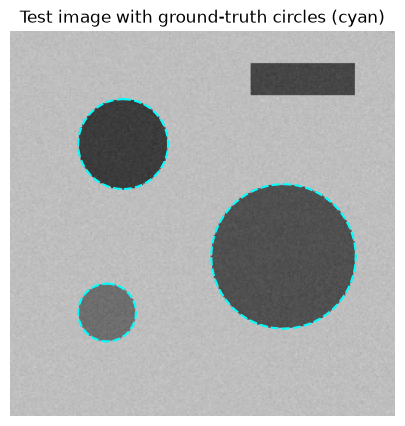

In [2]:
def make_test_image(seed=0):
    H = W = 240
    yy, xx = np.mgrid[0:H, 0:W]
    img = np.full((H, W), 190.0)
    truth = [(70, 70, 28, 60), (170, 140, 45, 80), (60, 175, 18, 110)]   # (cx, cy, r, grey value)
    for cx, cy, r, v in truth:
        img[(xx - cx) ** 2 + (yy - cy) ** 2 <= r ** 2] = v
    img[20:40, 150:215] = 70                                            # non-circular distractor
    img += np.random.default_rng(seed).normal(0, 4, img.shape)          # sensor-like noise
    return np.clip(img, 0, 255), truth

test, truth = make_test_image()
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(test, cmap="gray", vmin=0, vmax=255)
for cx, cy, r, _ in truth:
    ax.add_patch(plt.Circle((cx, cy), r, fill=False, ec="cyan", ls="--", lw=1.5))
ax.set_title("Test image with ground-truth circles (cyan)"); ax.axis("off")
plt.show()

**Plot explanation – test image.** The grey image is the input of the algorithm. The cyan dashed circles are the **ground truth** (centre and radius used to draw the discs); they are only drawn for checking and are not used by the algorithm. Three circles have clearly different sizes so that the radius search is tested, and the rectangle is there to check that straight edges do not produce circles.

## 3. Implementation, step by step
### Step 1 – Gaussian smoothing
Differentiation amplifies noise (a derivative reacts to every small jump). Blurring first with a Gaussian of width $\sigma$ lowers the noise so that the gradient reflects real edges.

### Step 2 – Sobel gradient
Two 3 × 3 kernels estimate the horizontal and vertical derivative (a derivative along one axis combined with smoothing along the other):

$$K_x=\begin{pmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{pmatrix},\quad K_y=K_x^{T},\qquad |G|=\sqrt{G_x^2+G_y^2},\quad \theta=\operatorname{atan2}(G_y,G_x)$$

$|G|$ is large where brightness changes quickly (edges); $\theta$ points across the edge, from dark to bright.

### Step 3 – Non-maximum suppression (thinning)
Gradient magnitude is wide across an edge. For every pixel we compare $|G|$ with its two neighbours **along the gradient direction** (quantised to 0°, 45°, 90°, 135°) and keep it only if it is the maximum. The result is a ~1-pixel-thin edge, which matters because every extra edge pixel would cast its own votes.

### Step 4 – Edge map
Pixels whose thinned magnitude exceeds `EDGE_FRAC` × maximum become edge pixels (value 1).

In [3]:
def smooth(img, sigma):
    return ndi.gaussian_filter(img, sigma, mode="reflect")                       # step 1

def sobel(img):
    kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)            # step 2
    gx = ndi.correlate(img, kx, mode="reflect")
    gy = ndi.correlate(img, kx.T, mode="reflect")
    return gx, gy, np.hypot(gx, gy), np.arctan2(gy, gx)

def non_max_suppression(mag, ang):
    a = np.rad2deg(ang) % 180                                                    # step 3
    q = np.select([a < 22.5, a < 67.5, a < 112.5, a < 157.5], [0, 1, 2, 3], 0)  # direction class
    shifts = {0: (0, 1), 1: (1, 1), 2: (1, 0), 3: (1, -1)}                       # (dy, dx) along the gradient
    out = np.zeros_like(mag)
    for k, (dy, dx) in shifts.items():
        n1 = np.roll(mag, (-dy, -dx), axis=(0, 1))
        n2 = np.roll(mag, (dy, dx), axis=(0, 1))
        keep = (q == k) & (mag > n1) & (mag >= n2)
        out[keep] = mag[keep]
    out[0, :] = out[-1, :] = 0; out[:, 0] = out[:, -1] = 0                       # remove wrap-around at the border
    return out

def edge_map(nms, frac):
    return nms >= frac * nms.max()                                               # step 4

blurred            = smooth(test, SIGMA)
gx, gy, mag, ang   = sobel(blurred)
nms                = non_max_suppression(mag, ang)
edges              = edge_map(nms, EDGE_FRAC)
print(f"edge pixels: {int(edges.sum())} of {edges.size} ({100 * edges.mean():.1f} %)")

edge pixels: 838 of 57600 (1.5 %)


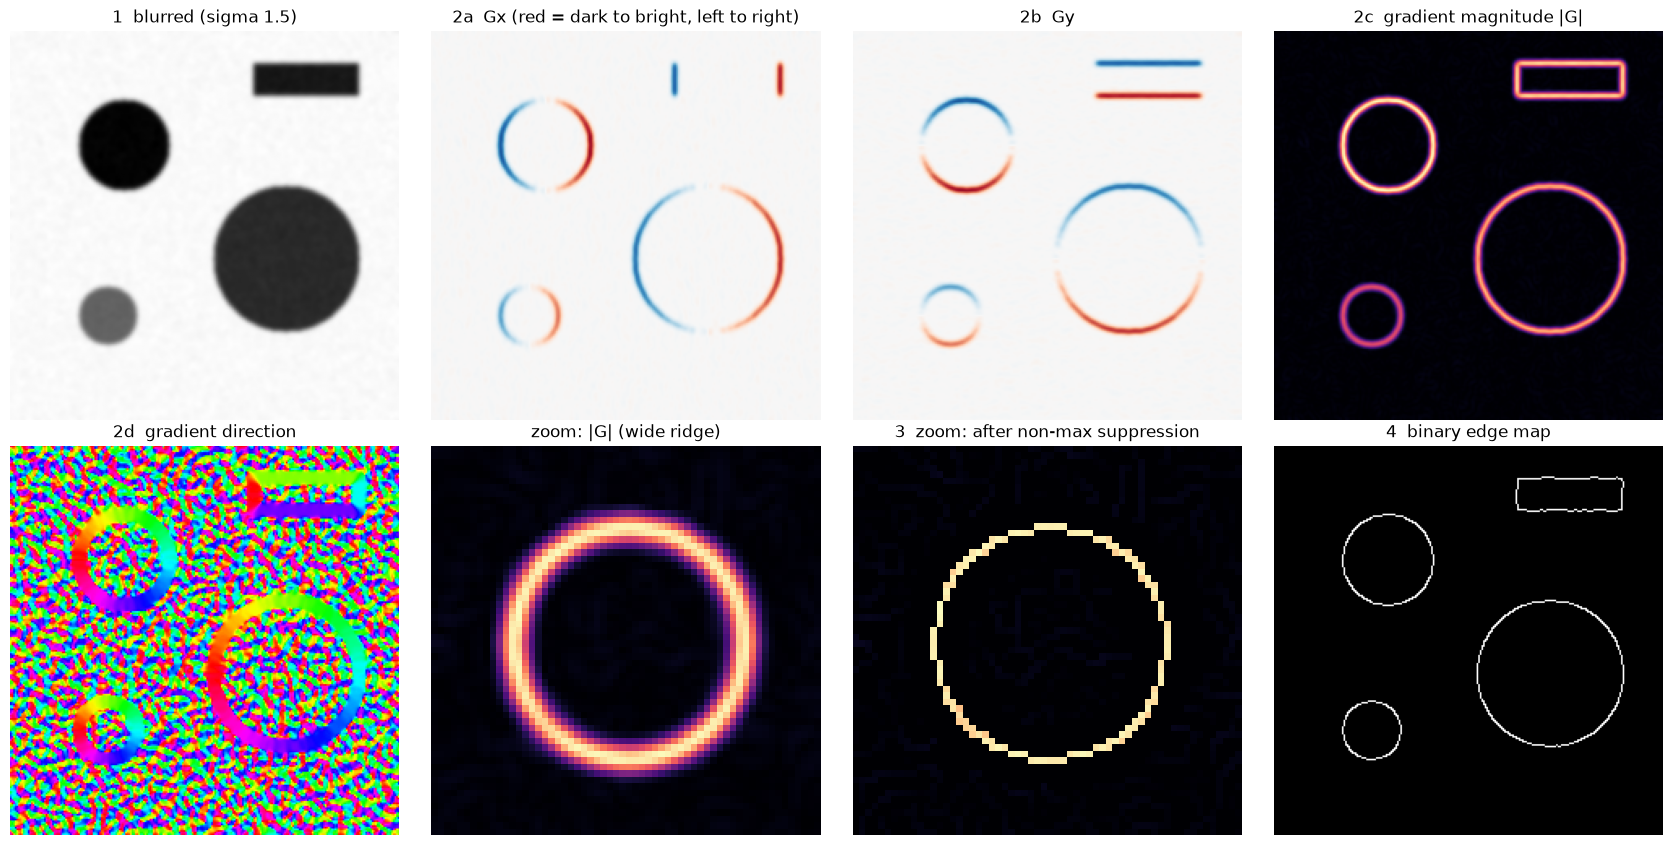

In [4]:
zx, zy = slice(145, 205), slice(30, 90)       # zoom on the smallest disc
fig, axs = plt.subplots(2, 4, figsize=(17, 8.5))
axs[0, 0].imshow(blurred, cmap="gray");                  axs[0, 0].set_title("1  blurred (sigma 1.5)")
axs[0, 1].imshow(gx, cmap="RdBu_r", vmin=-300, vmax=300); axs[0, 1].set_title("2a  Gx (red = dark to bright, left to right)")
axs[0, 2].imshow(gy, cmap="RdBu_r", vmin=-300, vmax=300); axs[0, 2].set_title("2b  Gy")
axs[0, 3].imshow(mag, cmap="magma");                     axs[0, 3].set_title("2c  gradient magnitude |G|")
axs[1, 0].imshow(ang, cmap="hsv", vmin=-np.pi, vmax=np.pi); axs[1, 0].set_title("2d  gradient direction")
axs[1, 1].imshow(mag[zx, zy], cmap="magma", interpolation="nearest"); axs[1, 1].set_title("zoom: |G| (wide ridge)")
axs[1, 2].imshow(nms[zx, zy], cmap="magma", interpolation="nearest"); axs[1, 2].set_title("3  zoom: after non-max suppression")
axs[1, 3].imshow(edges, cmap="gray");                    axs[1, 3].set_title("4  binary edge map")
for a in axs.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

**Plot explanation – edge detection steps.**
- **1 blurred:** the test image with the noise smoothed; edges are slightly softer.
- **2a / 2b:** the two Sobel derivatives as signed images (red = positive, blue = negative, white = 0). $G_x$ responds to vertical edges (left and right sides of a disc, with opposite signs), $G_y$ to horizontal edges (top and bottom). This sign pattern is what the direction image uses.
- **2c magnitude:** both derivatives combined; every outline is a bright ring, including the straight outline of the rectangle.
- **2d direction:** colour encodes the angle of the gradient. Around each disc the colour runs through the whole circle, because the gradient always points across the edge, i.e. along the radius. This is the property that Hough voting could exploit.
- **Zoom |G| vs. after NMS:** the same patch of the smallest disc. The magnitude is a ridge several pixels wide; after non-maximum suppression only the ridge line stays.
- **4 binary edge map:** the input of the Hough transform: white = edge pixel. The circles are closed rings, the rectangle shows straight lines, and some isolated noise pixels may remain.

### Step 5 – Hough voting, accumulator and peaks
For every radius $r$ in `RADII` and every edge pixel $(x,y)$ we add one vote to each cell $(a,b)=(x+r\cos t,\;y+r\sin t)$ for angles $t$ around the full circle (about one sample per pixel of circumference, $n_r=\lceil 2\pi r\rceil$). The accumulator has one 2-D layer per radius, so it is a 3-D array $A[r,\,b,\,a]$.

**Normalisation.** A circle of radius $r$ has about $2\pi r$ edge pixels, so large circles collect more votes than small ones. We divide the layer of radius $r$ by $n_r$: the value is then roughly the **fraction of the circumference** that is covered by edge pixels (≈ 1 for a complete circle). This makes `PEAK_THR` comparable across radii.

**Peak detection.** Keep the local maxima in a 5 × 5 × 5 neighbourhood of $(r,b,a)$ above `PEAK_THR`, sort them by value, and accept a peak only if it is at least `MIN_SEP` away (in $(a,b,r)$) from all accepted peaks. This removes duplicate detections of the same circle.

In [5]:
def hough_circle_accumulator(edge, radii):
    H, W = edge.shape
    ys, xs = np.nonzero(edge)
    acc = np.zeros((len(radii), H, W), dtype=np.float32)
    for i, r in enumerate(radii):
        n = int(np.ceil(2 * np.pi * r))
        t = np.linspace(0, 2 * np.pi, n, endpoint=False)
        cy = np.rint(ys[:, None] + r * np.sin(t)[None, :]).astype(int).ravel()    # candidate centres of all edge pixels
        cx = np.rint(xs[:, None] + r * np.cos(t)[None, :]).astype(int).ravel()
        ok = (cy >= 0) & (cy < H) & (cx >= 0) & (cx < W)
        votes = np.bincount(cy[ok] * W + cx[ok], minlength=H * W)                   # voting
        acc[i] = votes.reshape(H, W) / n                                            # normalise by circumference
    return acc

def find_circles(acc, radii, thr, min_sep):
    local_max = acc == ndi.maximum_filter(acc, size=(5, 5, 5), mode="constant")
    idx = np.argwhere(local_max & (acc >= thr))
    order = np.argsort(-acc[tuple(idx.T)])
    found = []
    for ri, cy, cx in idx[order]:
        c = (cx, cy, radii[ri])
        if all(np.linalg.norm(np.subtract(c, f[:3])) >= min_sep for f in found):
            found.append((int(cx), int(cy), int(radii[ri]), float(acc[ri, cy, cx])))
    return found

acc = hough_circle_accumulator(edges, RADII)
circles = find_circles(acc, RADII, PEAK_THR, MIN_SEP)
print("accumulator shape (radii, y, x):", acc.shape, "| maximum value:", round(float(acc.max()), 2))
print("detected circles (x, y, r, accumulator value):")
for c in circles: print("  ", c[:3], round(c[3], 2))

accumulator shape (radii, y, x): (49, 240, 240) | maximum value: 0.95
detected circles (x, y, r, accumulator value):
   (170, 140, 45) 0.95
   (70, 70, 28) 0.9
   (60, 175, 18) 0.85


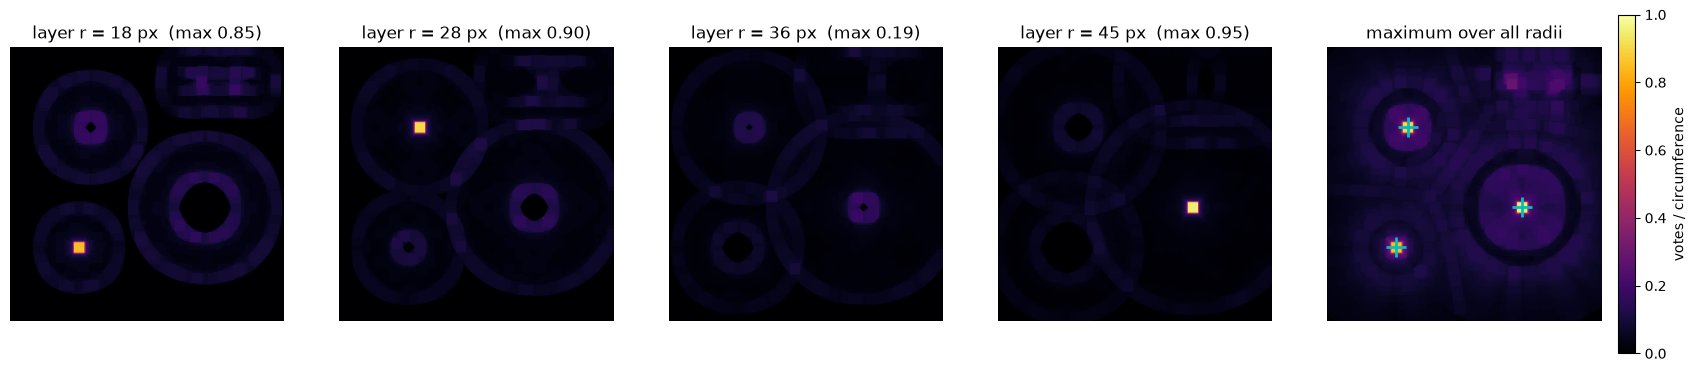

In [6]:
show_r = [18, 28, 36, 45]                                   # three true radii and one radius without a circle
fig, axs = plt.subplots(1, 5, figsize=(21, 4.4))
for a, r in zip(axs[:4], show_r):
    layer = acc[list(RADII).index(r)]
    m = a.imshow(ndi.maximum_filter(layer, size=9), cmap="inferno", vmin=0, vmax=1.0)   # 9x9 max filter for display only
    a.set_title(f"layer r = {r} px  (max {layer.max():.2f})"); a.axis("off")
axs[4].imshow(ndi.maximum_filter(acc.max(axis=0), size=9), cmap="inferno", vmin=0, vmax=1.0); axs[4].set_title("maximum over all radii"); axs[4].axis("off")
for cx, cy, r, _ in circles:
    axs[4].plot(cx, cy, "c+", ms=14, mew=2)
fig.colorbar(m, ax=axs, fraction=0.012, pad=0.01, label="votes / circumference")
plt.show()

**Plot explanation – accumulator space.** Each panel is one layer of the 3-D accumulator, i.e. the votes for circle *centres* if all circles had that one radius; bright = many edge pixels agree on that centre. For visibility the layers are drawn with a 9 × 9 maximum filter, which only enlarges the peaks (the data are unchanged); the number in each title is the true maximum of the layer.
- **r = 18, 28, 45:** each layer contains one bright **peak** at the centre of the disc that has this radius, because all edge pixels of that disc cast a vote for exactly this cell. The ring-shaped faint structures are the votes of the other discs, which spread out over many cells instead of meeting in one point.
- **r = 36:** no disc has this radius, so the layer has no bright peak and its maximum stays clearly below the other three layers.
- **Maximum over all radii:** collapses the radius axis; every disc leaves one bright point at its centre. The cyan crosses are the peaks chosen in step 5.
- The colour bar is the normalised value ("fraction of circumference covered"); values near 1 mean an almost complete circle.

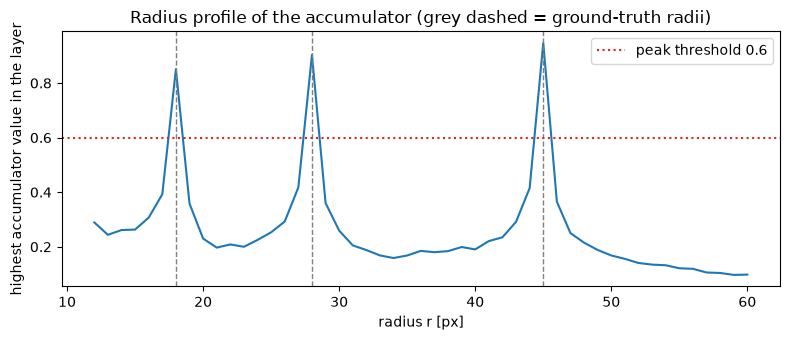

In [7]:
prof = acc.reshape(len(RADII), -1).max(axis=1)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(RADII, prof, color="tab:blue")
for _, _, r, _ in truth: ax.axvline(r, color="gray", ls="--", lw=1)
ax.axhline(PEAK_THR, color="tab:red", ls=":", label=f"peak threshold {PEAK_THR}")
ax.set_xlabel("radius r [px]"); ax.set_ylabel("highest accumulator value in the layer")
ax.set_title("Radius profile of the accumulator (grey dashed = ground-truth radii)"); ax.legend()
plt.tight_layout(); plt.show()

**Plot explanation – radius profile.** For each radius the plot shows the **highest value anywhere in that layer**, i.e. how well the best centre fits a circle of that radius. Peaks appear exactly at the radii of the discs (grey dashed lines) and between them the curve stays low. The red dotted line is `PEAK_THR`: only maxima above it can become detections. This is the third axis of the accumulator that the 2-D layers hide.

## 4. Verification on the test image
The detections are compared with the known ground truth (functional check of the code, not an evaluation of the method on a use case).

truth (x, y, r)     detected (x, y, r)    error dx, dy, dr    
(70, 70, 28)        (70, 70, 28)          (0, 0, 0)           
(170, 140, 45)      (170, 140, 45)        (0, 0, 0)           
(60, 175, 18)       (60, 175, 18)         (0, 0, 0)           

number of detections: 3 (ground truth: 3) | largest error: 0 px


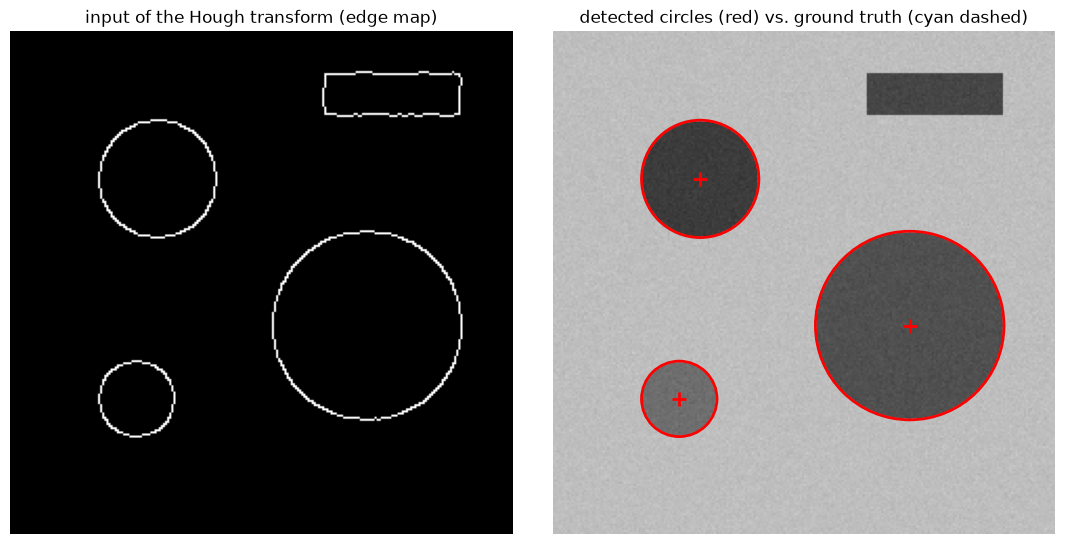

In [8]:
print(f"{'truth (x, y, r)':<20}{'detected (x, y, r)':<22}{'error dx, dy, dr':<20}")
errs = []
for cx, cy, r, _ in truth:
    d = min(circles, key=lambda c: np.hypot(c[0] - cx, c[1] - cy) + abs(c[2] - r))
    e = (d[0] - cx, d[1] - cy, d[2] - r); errs.append(max(abs(v) for v in e))
    print(f"{str((cx, cy, r)):<20}{str(tuple(int(v) for v in d[:3])):<22}{str(tuple(int(v) for v in e)):<20}")
print(f"\nnumber of detections: {len(circles)} (ground truth: {len(truth)}) | largest error: {max(errs)} px")
assert len(circles) == len(truth) and max(errs) <= 2, "verification failed"

fig, axs = plt.subplots(1, 2, figsize=(11, 5.4))
axs[0].imshow(edges, cmap="gray"); axs[0].set_title("input of the Hough transform (edge map)")
axs[1].imshow(test, cmap="gray", vmin=0, vmax=255); axs[1].set_title("detected circles (red) vs. ground truth (cyan dashed)")
for cx, cy, r, _ in truth:  axs[1].add_patch(plt.Circle((cx, cy), r, fill=False, ec="cyan", ls="--", lw=1.5))
for cx, cy, r, _ in circles:
    axs[1].add_patch(plt.Circle((cx, cy), r, fill=False, ec="red", lw=2)); axs[1].plot(cx, cy, "r+", ms=10, mew=2)
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

**Plot explanation – detection result.** Left: the edge map that went into the transform. Right: the final circles, drawn in red with a red cross at the centre, on top of the test image; the cyan dashed circles are the ground truth. Where red and cyan lie on top of each other, centre and radius were recovered correctly; the table above gives the exact differences in pixels. The rectangle produced no circle, because its straight edges do not make a consistent vote for any single centre. The `assert` stops the notebook if the number of detections or the position error is outside the tolerance (≤ 2 px).

## 5. Summary of the implementation
Blur, Sobel gradient, non-maximum suppression and thresholding were implemented separately and every intermediate result was shown. The Hough accumulator (radius × y × x) was built by explicit voting, normalised by circumference, reduced to circles by local-maximum search with a minimum-separation rule, and verified against a test image with known circles. All parameters are listed in one cell. Which image, use case and parameter settings are meaningful for a real photograph is addressed from Day 7 onwards.